Random Forest - Credential-based Intrusion Detection

1. Imports

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             precision_score, recall_score,
                             confusion_matrix, classification_report)

In [26]:
df = pd.read_csv("/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv")
print(df.shape)
print(df["label"].value_counts(dropna=False))

/tmp/ipykernel_50/3914520064.py:1: DtypeWarning: Columns (2,4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv")


(1003030, 22)
label
0.0    501998
1.0    501032
Name: count, dtype: int64


Value counts in label column:
label
0.0    501998
1.0    501032
Name: count, dtype: int64


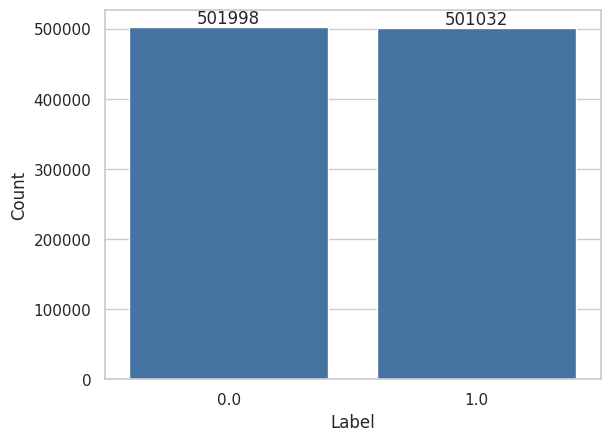

In [27]:
sns.set_theme(style="whitegrid")

ax = sns.countplot(x='label', data=df, color='#3572B0')
ax.bar_label(ax.containers[0])
plt.xlabel('Label', fontsize=12)
plt.ylabel('Count', fontsize=12)
print("Value counts in label column:")
print(df['label'].value_counts())

plt.show()

2. Configuration

In [28]:
IP_COL, USER_COL, LOC_COL, ASN_COL = "src_ip", "username", "location", "asn"
SEED = 42

Q = dict(v_fast=0.05, fast=0.20, v_reg=0.10, reg=0.30, failure=0.95)

FEATURES = [
    "hr", "dow", "is_wknd", "is_night",
    "p_len", "p_comp", "has_num", "has_spec", "p_score",
    "u_freq", "loc_freq", "asn_freq",
    "mean_iat", "std_iat", "iat_var", "is_v_fast", "is_fast", "is_reg", "is_v_reg",
    "tries", "fails", "fail_rate", "is_failure",
]

assert len(FEATURES) == 23 and len(set(FEATURES)) == 23
assert "has_num" in FEATURES

3. Feature Engineering and Split Functions

In [29]:
def build_row_features(df):
    X = df.copy()
    ts = pd.to_datetime(X["timestamp"], format="mixed", errors="coerce")
    missing = ts.isna()
    X["hr"] = ts.dt.hour.fillna(0).astype("int8")
    X["dow"] = ts.dt.dayofweek.fillna(0).astype("int8")
    X["is_wknd"] = (X["dow"].isin([4, 5]) & ~missing).astype("int8")
    X["is_night"] = (((X["hr"] < 6) | (X["hr"] >= 23)) & ~missing).astype("int8")

    X["p_len"] = pd.to_numeric(X["password_length"], errors="coerce").fillna(0).astype("int16")
    X["p_comp"] = pd.to_numeric(X["password_complexity"], errors="coerce").fillna(0).astype("int16")
    pw = X["password"].astype(str)
    X["has_num"] = pw.str.contains(r"\d", regex=True).astype("int8")
    X["has_spec"] = pw.str.contains(r"[^\w\s]|_", regex=True).astype("int8")
    X["p_score"] = ((X["p_comp"] * X["p_len"]) / 10).astype("float32")

    X["mean_iat"] = pd.to_numeric(X["mean_iat"], errors="coerce").fillna(0).astype("float32")
    X["std_iat"] = pd.to_numeric(X["std_iat"], errors="coerce").fillna(0).astype("float32")
    X["iat_var"] = (X["std_iat"].astype("float64") ** 2).astype("float32")

    X["tries"] = pd.to_numeric(X["login_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fails"] = pd.to_numeric(X["fail_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fail_rate"] = pd.to_numeric(X["fail_ratio"], errors="coerce").fillna(0).astype("float32")

    X[USER_COL] = X[USER_COL].astype(str)
    X["target"] = X["label"].astype("int8")
    return X


def group_split(X_all):
    g1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
    tr, tmp = next(g1.split(X_all, X_all["target"], groups=X_all[IP_COL]))
    train, temp = X_all.iloc[tr].copy(), X_all.iloc[tmp].copy()
    g2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
    va, te = next(g2.split(temp, temp["target"], groups=temp[IP_COL]))
    val, test = temp.iloc[va].copy(), temp.iloc[te].copy()
    a, b, c = set(train[IP_COL]), set(val[IP_COL]), set(test[IP_COL])
    assert a.isdisjoint(b) and a.isdisjoint(c) and b.isdisjoint(c), "IP overlap!"
    return train, val, test


class TrainFitted:
    def fit(self, train):
        self.u_map = train[USER_COL].value_counts(normalize=True)
        self.loc_map = train[LOC_COL].value_counts(normalize=True)
        self.asn_map = train[ASN_COL].value_counts(normalize=True)
        q = lambda c, p: float(train[c].quantile(p))
        self.t = dict(v_fast=q("mean_iat", Q["v_fast"]), fast=q("mean_iat", Q["fast"]),
                      v_reg=q("std_iat", Q["v_reg"]), reg=q("std_iat", Q["reg"]),
                      failure=q("fail_rate", Q["failure"]))
        return self

    def transform(self, df):
        d, t = df.copy(), self.t
        d["u_freq"] = d[USER_COL].map(self.u_map).fillna(0).astype("float32")
        d["loc_freq"] = d[LOC_COL].map(self.loc_map).fillna(0).astype("float32")
        d["asn_freq"] = d[ASN_COL].map(self.asn_map).fillna(0).astype("float32")
        d["is_v_fast"] = (d["mean_iat"] < t["v_fast"]).astype("int8")
        d["is_fast"] = ((d["mean_iat"] >= t["v_fast"]) & (d["mean_iat"] < t["fast"])).astype("int8")
        d["is_v_reg"] = (d["std_iat"] < t["v_reg"]).astype("int8")
        d["is_reg"] = ((d["std_iat"] >= t["v_reg"]) & (d["std_iat"] < t["reg"])).astype("int8")
        d["is_failure"] = (d["fail_rate"] >= t["failure"]).astype("int8")
        return d


def featurize(train, val, test):
    st = TrainFitted().fit(train)
    tr, va, te = st.transform(train), st.transform(val), st.transform(test)
    return dict(X_train=tr[FEATURES], y_train=tr["target"],
                X_val=va[FEATURES], y_val=va["target"],
                X_test=te[FEATURES], y_test=te["target"])

4. Data Preparation

In [30]:
X_all = build_row_features(df)
train, val, test = group_split(X_all)
S = featurize(train, val, test)

X_train, y_train = S["X_train"], S["y_train"]
X_val,   y_val   = S["X_val"],   S["y_val"]
X_test,  y_test  = S["X_test"],  S["y_test"]

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts())

(755190, 23) (129328, 23) (118512, 23)
target
1    388585
0    366605
Name: count, dtype: int64


5. Split Sizes

In [31]:
splits = {"Train": train, "Validation": val, "Test": test}
sizes_df = pd.DataFrame({
    "Split": list(splits.keys()),
    "Rows": [len(d) for d in splits.values()],
    "Unique IPs": [d[IP_COL].nunique() for d in splits.values()],
    "Normal": [int((d["target"] == 0).sum()) for d in splits.values()],
    "Attack": [int((d["target"] == 1).sum()) for d in splits.values()],
})
sizes_df["Attack %"] = (sizes_df["Attack"] / sizes_df["Rows"] * 100).round(2)
sizes_df

,Split,Rows,Unique IPs,Normal,Attack,Attack %
0,Train,755190,60122,366605,388585,51.46
1,Validation,129328,12883,68372,60956,47.13
2,Test,118512,12884,67021,51491,43.45


6. Hyperparameter Search (selected on validation only)

In [32]:
configs = [
    dict(max_depth=None, min_samples_leaf=5,  max_features="sqrt"),
    dict(max_depth=None, min_samples_leaf=10, max_features="sqrt"),
    dict(max_depth=None, min_samples_leaf=20, max_features="sqrt"),
    dict(max_depth=None, min_samples_leaf=40, max_features="sqrt"),
    dict(max_depth=None, min_samples_leaf=10, max_features=0.5),
    dict(max_depth=20,   min_samples_leaf=10, max_features="sqrt"),
]

rng = np.random.RandomState(SEED)
pos = rng.choice(len(X_train), size=min(250000, len(X_train)), replace=False)
X_s, y_s = X_train.iloc[pos], y_train.iloc[pos]

search_rows = []
for i, cfg in enumerate(configs):
    m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED, **cfg).fit(X_s, y_s)
    p = m.predict_proba(X_val)[:, 1]
    search_rows.append({
        "Config": i,
        "max_depth": cfg["max_depth"],
        "min_samples_leaf": cfg["min_samples_leaf"],
        "max_features": cfg["max_features"],
        "Val Accuracy (%)": round(accuracy_score(y_val, (p >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_val, p), 4),
    })

search_df = pd.DataFrame(search_rows)
best_params = configs[int(search_df["Val ROC-AUC"].idxmax())]
print("Best params:", best_params)
search_df

Best params: {'max_depth': None, 'min_samples_leaf': 10, 'max_features': 0.5}


,Config,max_depth,min_samples_leaf,max_features,Val Accuracy (%),Val ROC-AUC
0,0,NaN,5,sqrt,85.10,0.9322
1,1,NaN,10,sqrt,85.30,0.9321
2,2,NaN,20,sqrt,85.20,0.9318
3,3,NaN,40,sqrt,85.02,0.9305
4,4,NaN,10,0.5,85.96,0.9369
5,5,20.0,10,sqrt,85.16,0.9328


7. Model Creation

In [33]:
rf = RandomForestClassifier(
    n_estimators=500,
    n_jobs=-1,
    random_state=SEED,
    **best_params
)

8. Training and Threshold Selection

In [ ]:
rf.fit(X_train, y_train)

p_train = rf.predict_proba(X_train)[:, 1]
p_val = rf.predict_proba(X_val)[:, 1]
p_test = rf.predict_proba(X_test)[:, 1]

grid = np.arange(0.30, 0.701, 0.01)
f1_grid = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
thr = float(grid[int(np.argmax(f1_grid))])
print("Selected threshold:", round(thr, 2))

In [ ]:
print("--- Random Forest Hyperparameters ---")

print("n_estimators:", rf.n_estimators)

print("Best Params from Tuning:", rf.get_params())

9. Final Results Table

In [ ]:
def result_row(name, y, p, t):
    pred = (p >= t).astype(int)
    return {
        "Experiment": name,
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 2),
        "Precision (%)": round(precision_score(y, pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y, pred, zero_division=0) * 100, 2),
        "F1 (%)": round(f1_score(y, pred, zero_division=0) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y, p), 4),
    }

results_df = pd.DataFrame([
    result_row("Validation (threshold 0.50)", y_val, p_val, 0.5),
    result_row("Test (threshold 0.50)", y_test, p_test, 0.5),
    result_row(f"Validation (threshold {thr:.2f})", y_val, p_val, thr),
    result_row(f"Test (threshold {thr:.2f})", y_test, p_test, thr),
])

sizes_df.to_csv("rf_split_sizes.csv", index=False)
search_df.to_csv("rf_hyperparameter_search.csv", index=False)
results_df.to_csv("rf_final_results.csv", index=False)
results_df

10. Model Evaluation

Accuracy Scores:
  • Training: 0.9602
  • Test: 0.8200
  • Validation: 0.8626
  • F1-Score (Weighted): 0.8198
Unique in y_test: [0 1]
Unique in y_test_pred: [0 1]


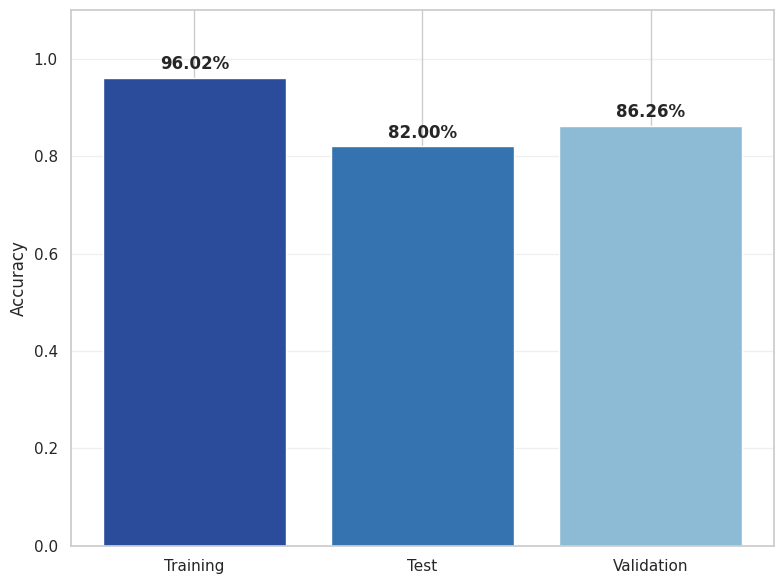

In [37]:
y_train_pred = (p_train >= thr).astype(int)
y_val_pred = (p_val >= thr).astype(int)
y_test_pred = (p_test >= thr).astype(int)

y_test_prob = np.column_stack([1 - p_test, p_test])

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')

print("Accuracy Scores:")
print(f"  • Training: {train_acc:.4f}")
print(f"  • Test: {test_acc:.4f}")
print(f"  • Validation: {val_acc:.4f}")
print(f"  • F1-Score (Weighted): {test_f1:.4f}")

print("Unique in y_test:", np.unique(y_test))
print("Unique in y_test_pred:", np.unique(y_test_pred))

plt.figure(figsize=(8, 6))
accuracies = [train_acc, test_acc, val_acc]
bars = plt.bar(['Training', 'Test', 'Validation'], accuracies,
               color=['#2B4C9B', '#3572B0', '#8DBBD5'])

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
             f'{acc:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

11. Class Distribution

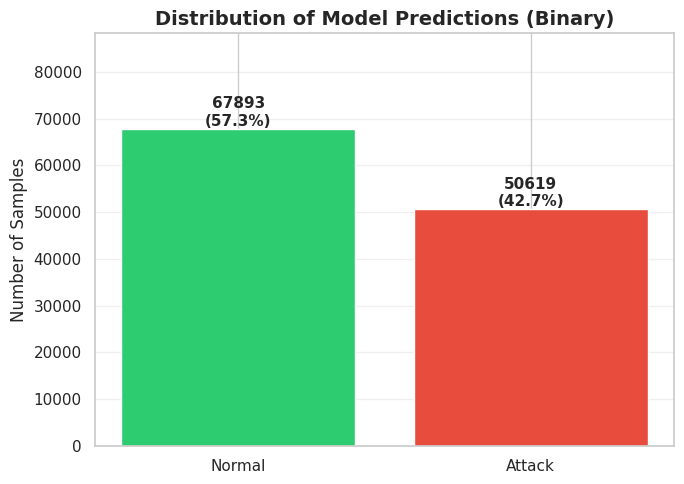

In [38]:
plt.figure(figsize=(7, 5))
colors = ['#2ECC71', '#E74C3C']

class_names = ['Normal', 'Attack']

class_counts = pd.Series(y_test_pred).value_counts().sort_index()
total = len(y_test_pred)

bars = plt.bar(class_names, [class_counts.get(i, 0) for i in range(2)], color=colors)

plt.ylim(0, class_counts.max() * 1.3)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}\n({height/total*100:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Distribution of Model Predictions (Binary)', fontsize=14, fontweight='bold')
plt.ylabel('Number of Samples', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

12. Mutual Information

Top 15 Mutual Information Scores:
       Feature  MI_Score
11    asn_freq  0.266377
10    loc_freq  0.193346
13     std_iat  0.191986
12    mean_iat  0.188815
21   fail_rate  0.132310
9       u_freq  0.127680
20       fails  0.108089
14     iat_var  0.097292
19       tries  0.074336
22  is_failure  0.047422
17      is_reg  0.040763
0           hr  0.031357
6      has_num  0.031162
3     is_night  0.018486
16     is_fast  0.016429


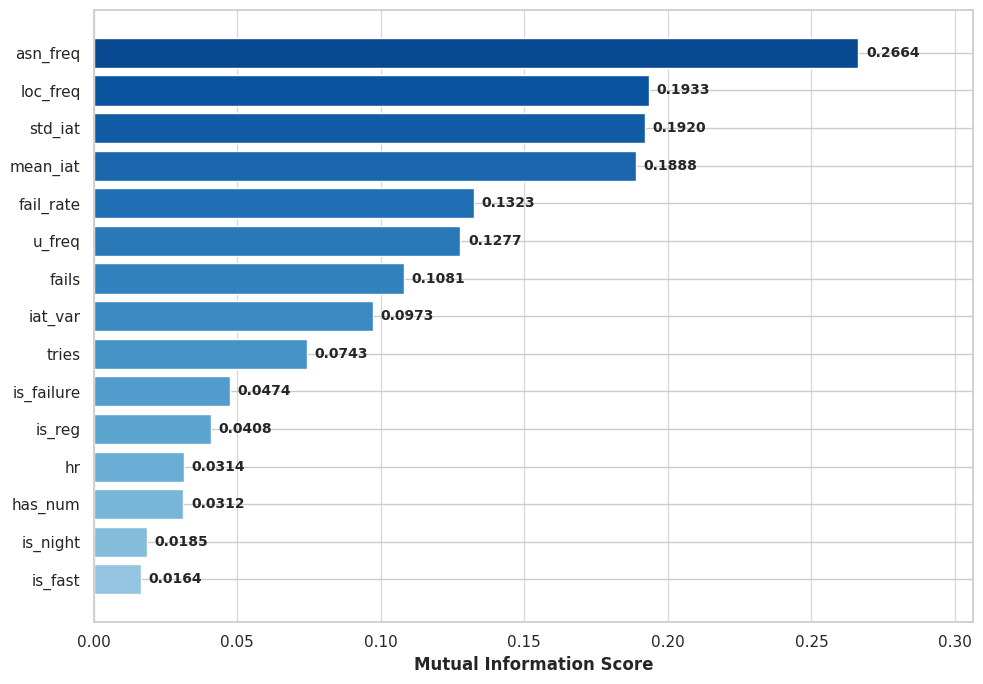

In [39]:
feature_columns = X_train.columns

X_train_df = X_train.fillna(0)

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_df), size=min(20000, len(X_train_df)), replace=False)
X_sample = X_train_df.iloc[sample_idx]
y_sample = y_train.iloc[sample_idx]

mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)

mi_df = pd.DataFrame({
    'Feature': feature_columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Top 15 Mutual Information Scores:")
print(mi_df.head(15))

plt.figure(figsize=(10, 7))
top_15_mi = mi_df.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15_mi)))

bars = plt.barh(range(len(top_15_mi)), top_15_mi['MI_Score'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15_mi)), top_15_mi['Feature'].values)
plt.xlabel('Mutual Information Score', fontsize=12, fontweight='bold')

plt.gca().invert_yaxis()
plt.xlim(0, top_15_mi['MI_Score'].max() * 1.15)

for i, (bar, val) in enumerate(zip(bars, top_15_mi['MI_Score'].values)):
    plt.text(
        bar.get_width() + (top_15_mi['MI_Score'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.4f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

13. Feature Importance

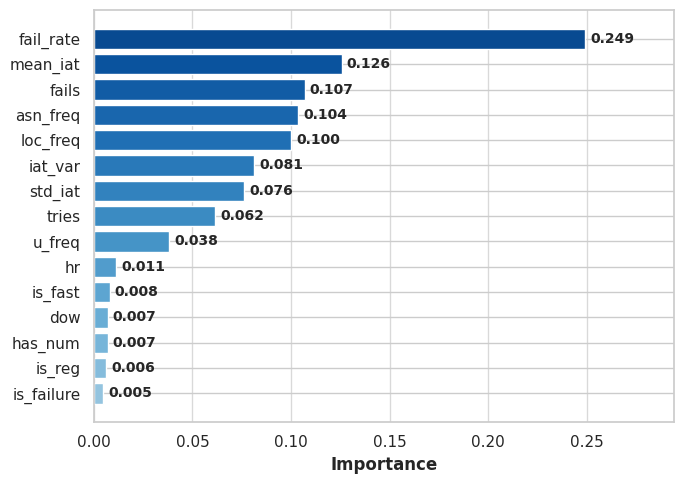

In [40]:
feature_columns = X_train.columns

importances = rf.feature_importances_

top_features = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(7, 5))
top_15 = top_features.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15)))
bars = plt.barh(range(len(top_15)), top_15['Importance'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15)), top_15['Feature'].values)
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, top_15['Importance'].max() * 1.18)
for i, (bar, val) in enumerate(zip(bars, top_15['Importance'].values)):
    plt.text(
        bar.get_width() + (top_15['Importance'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.3f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

14. Classification Report

In [42]:
report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=['Normal', 'Attack'],
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()

for col in ['precision', 'recall', 'f1-score']:
    df_report[col] = df_report[col].apply(lambda x: f"{x*100:.2f}%")

display(df_report)

,precision,recall,f1-score,support
Normal,83.65%,84.74%,84.19%,67021.000000
Attack,79.79%,78.44%,79.11%,51491.000000
accuracy,82.00%,82.00%,82.00%,0.820018
macro avg,81.72%,81.59%,81.65%,118512.000000
weighted avg,81.97%,82.00%,81.98%,118512.000000


 15. Pearson Correlation Matrix

In [43]:
# 1. Calculate the threshold using positive training values only
positive_iat = X_train.loc[
    X_train['mean_iat'] > 0, 'mean_iat'
]

fast_limit = positive_iat.quantile(0.05)

print("New Fast Threshold:", fast_limit)

# 2. Recalculate is_v_fast in all datasets
for ds in [X_train, X_val, X_test]:
    ds['is_v_fast'] = (
        (ds['mean_iat'] > 0) &
        (ds['mean_iat'] <= fast_limit)
    ).astype('int8')

# 3. Check the results
print("\nTrain distribution:")
print(X_train['is_v_fast'].value_counts())

print("\nValidation distribution:")
print(X_val['is_v_fast'].value_counts())

print("\nTest distribution:")
print(X_test['is_v_fast'].value_counts())

New Fast Threshold: 2.8081481099128722

Train distribution:
is_v_fast
0    720449
1     34741
Name: count, dtype: int64

Validation distribution:
is_v_fast
0    124199
1      5129
Name: count, dtype: int64

Test distribution:
is_v_fast
0    116797
1      1715
Name: count, dtype: int64


In [44]:
FEATURES = [
    'hr', 'dow', 'is_wknd', 'is_night',
    'p_len', 'p_comp', 'has_num', 'has_spec',
    'p_score', 'u_freq', 'loc_freq', 'asn_freq',
    'mean_iat', 'std_iat', 'iat_var',
    'is_v_fast', 'is_fast', 'is_reg', 'is_v_reg',
    'tries', 'fails', 'fail_rate', 'is_failure'
]

X_train_final = X_train[FEATURES].copy()
X_val_final = X_val[FEATURES].copy()
X_test_final = X_test[FEATURES].copy()

print("Train shape:", X_train_final.shape)
print("Validation shape:", X_val_final.shape)
print("Test shape:", X_test_final.shape)

Train shape: (755190, 23)
Validation shape: (129328, 23)
Test shape: (118512, 23)


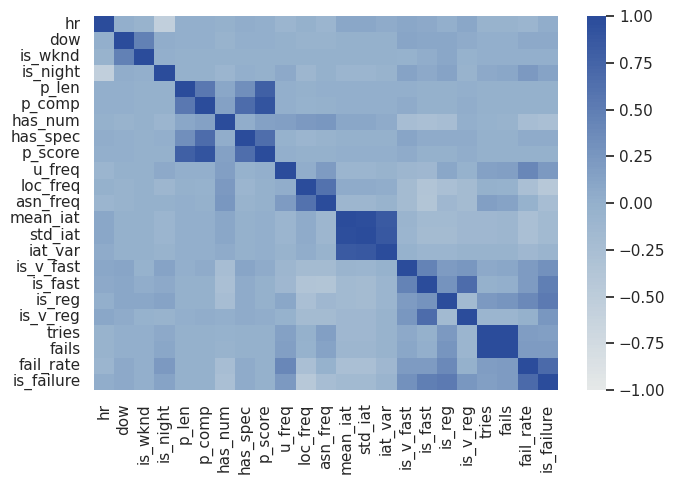

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Calculate correlation
corr_matrix = X_train_final.corr(method='pearson')

# Color palette
colors = ["#E5E8E8", "#94B0CC", "#2B4C9B"]

custom_cmap = LinearSegmentedColormap.from_list(
    "gray_to_blue", colors, N=100
)

# Plot
plt.figure(figsize=(7, 5))
sns.set_style("white")

sns.heatmap(
    corr_matrix,
    cmap=custom_cmap,
    annot=False,
    vmin=-1,
    vmax=1,
    center=0
)

plt.tight_layout()
plt.show()



16. Confusion Matrix

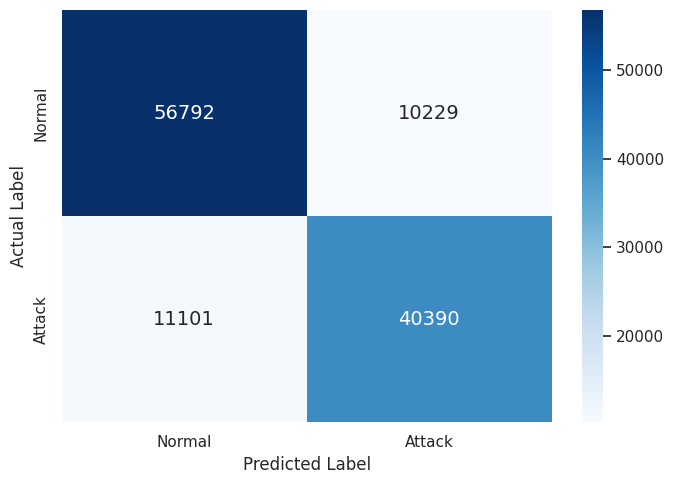

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"],
    annot_kws={"size": 14}
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.tight_layout()
plt.savefig(
    "XGBoost_Confusion_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

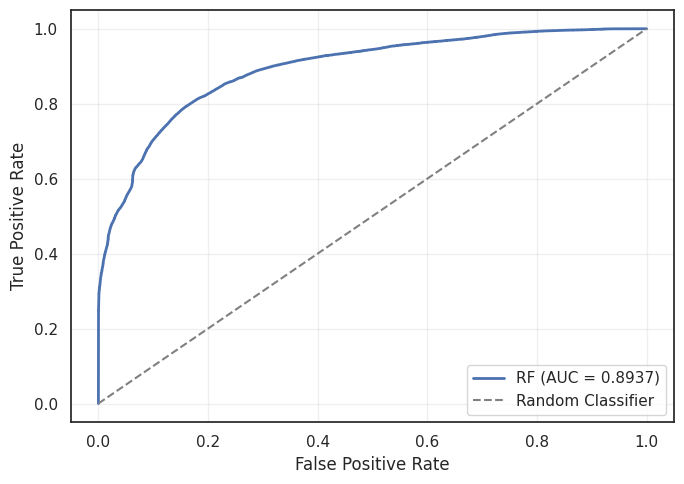

ROC-AUC: 0.8937


In [49]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_score = rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_score,
    pos_label=1
)

auc_value = roc_auc_score(y_test, y_score)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"RF (AUC = {auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)


plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "XGBoost_ROC_Curve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", round(auc_value, 4))

17. Classification Report Heatmap

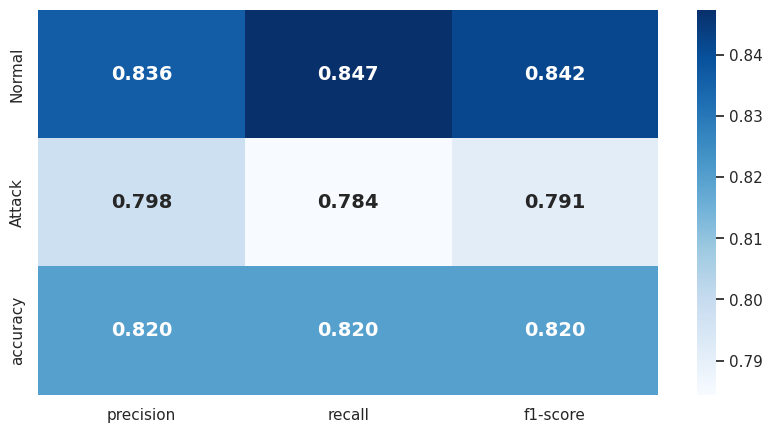

In [50]:
report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=['Normal', 'Attack'],
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).iloc[:-1, :3].T

plt.figure(figsize=(10, 5))
sns.heatmap(report_df, annot=True, fmt=".3f",
            cmap="Blues", annot_kws={"size": 14, "weight": "bold"})
plt.show()

18. Operational Performance and Security Metrics

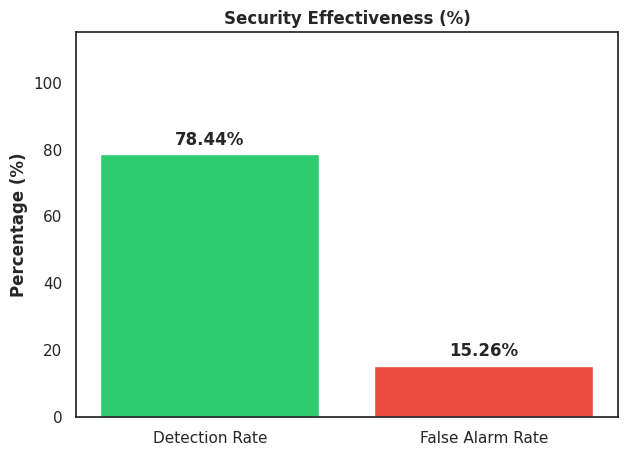

In [51]:
attack_recall = report['Attack']['recall']
normal_recall = report['Normal']['recall']

detection_rate = attack_recall * 100
far_rate = (1 - normal_recall) * 100

fig, ax1 = plt.subplots(figsize=(7, 5))

metrics = ['Detection Rate', 'False Alarm Rate']
values = [detection_rate, far_rate]

ax1.bar(metrics, values, color=['#2ECC71', '#E74C3C'])

ax1.set_ylim(0, 115)
ax1.set_title('Security Effectiveness (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Percentage (%)', fontweight='bold')

for i, v in enumerate(values):
    ax1.text(i, v + 3, f"{v:.2f}%", ha='center', fontweight='bold')

plt.show()

In [52]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import lime.lime_tabular
from sklearn.metrics import accuracy_score, f1_score, classification_report

class_names = ['Normal', 'Attack']

SHAP Explanation

SHAP Beeswarm Plots

In [53]:
background_for_explainer = X_train[:100]

X_sample_for_explainer = X_test[:50]

X_sample_for_plot = X_test[:50]

In [ ]:
print("SHAP Explanation (Random Forest):")

explainer = shap.Explainer(rf)

shap_values = explainer(X_sample_for_explainer)

if len(shap_values.values.shape) == 3:
    actual_shap_values = shap_values.values[:, :, 1]
else:
    actual_shap_values = shap_values.values

print(f"SHAP values shape: {actual_shap_values.shape}")

SHAP Explanation (Random Forest):
SHAP values shape: (50, 23)


In [ ]:
# Extract SHAP values for each class
shap_values_class_0 = shap_values.values[:, :, 0]
shap_values_class_1 = shap_values.values[:, :, 1]

In [ ]:
feature_names_list = X_train.columns.tolist()


Beeswarm Plot - Class 0 (Normal)


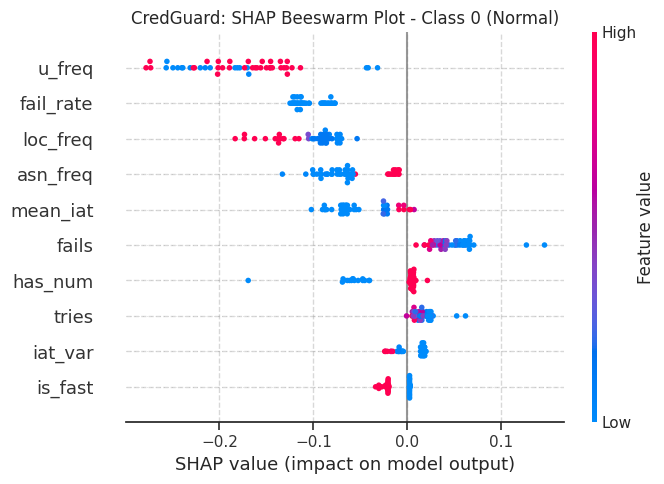


Beeswarm Plot - Class 1 (Attack)


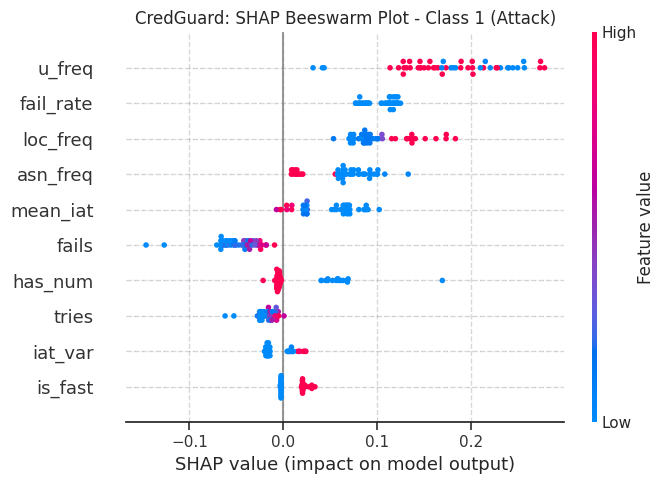

In [ ]:
print("\nBeeswarm Plot - Class 0 (Normal)")
shap.summary_plot(
    shap_values_class_0,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(7, 5),
    show=False
)
plt.title("CredGuard: SHAP Beeswarm Plot - Class 0 (Normal)")
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

print("\nBeeswarm Plot - Class 1 (Attack)")
shap.summary_plot(
    shap_values_class_1,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(7, 5),
    show=False
)
plt.title("CredGuard: SHAP Beeswarm Plot - Class 1 (Attack)")
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

SHAP Global Feature Importance


Global SHAP Feature Importance - All Features
Number of features: 23
Number of SHAP values: 23


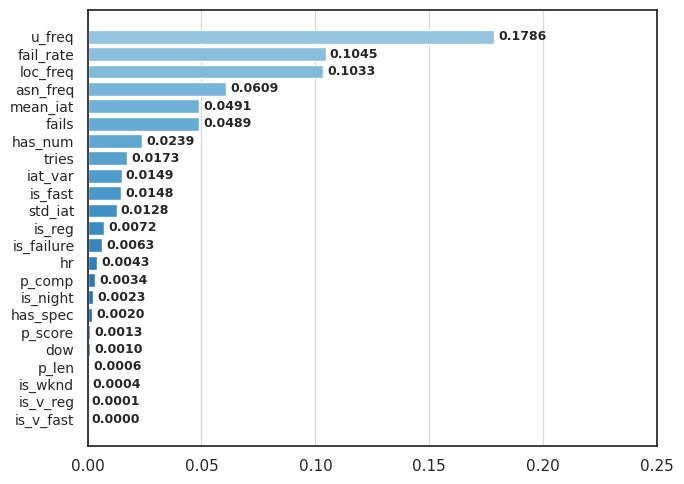

,Feature,mean(|SHAP value|)
0,u_freq,0.1786
1,fail_rate,0.1045
2,loc_freq,0.1033
3,asn_freq,0.0609
4,mean_iat,0.0491
5,fails,0.0489
6,has_num,0.0239
7,tries,0.0173
8,iat_var,0.0149
9,is_fast,0.0148


In [66]:
print("\nGlobal SHAP Feature Importance - All Features")

sv = np.mean(np.abs(shap_values.values), axis=2)
importance_all = np.mean(sv, axis=0)

feature_names = np.array(feature_names_list)

print("Number of features:", len(feature_names))
print("Number of SHAP values:", len(importance_all))

assert len(feature_names) == len(importance_all), \
    "Mismatch between feature names and SHAP values!"

indices_sorted = np.argsort(importance_all)[::-1]

labels_for_plot = feature_names[indices_sorted].tolist()
importance_sorted = importance_all[indices_sorted]

n_features = len(labels_for_plot)

plt.figure(figsize=(7, 5))

colors = plt.cm.Blues(
    np.linspace(0.4, 0.9, n_features)
)

bars = plt.barh(
    range(n_features),
    importance_sorted[::-1],
    color=colors[::-1]
)

plt.yticks(
    range(n_features),
    labels_for_plot[::-1],
    fontsize=10
)

# Grid
plt.grid(
    visible=True,
    axis='x',
    color='black',
    linestyle='-',
    alpha=0.15
)

plt.xlim(0, 0.25)
plt.xticks(np.arange(0, 0.251, 0.05))

for bar, val in zip(bars, importance_sorted[::-1]):
    plt.text(
        bar.get_width() + max_importance * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.4f}',
        va='center',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    'SHAP_Global_Feature_Importance_All23.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

# Create DataFrame containing all features
shap_importance_df = pd.DataFrame({
    'Feature': labels_for_plot,
    'mean(|SHAP value|)': importance_sorted.round(4)
})

# Display all 23 features
display(shap_importance_df)

LIME Explanation


Selected Sample: 16313
True Label: Normal
RF Prediction: Normal (Confidence: 0.8210)


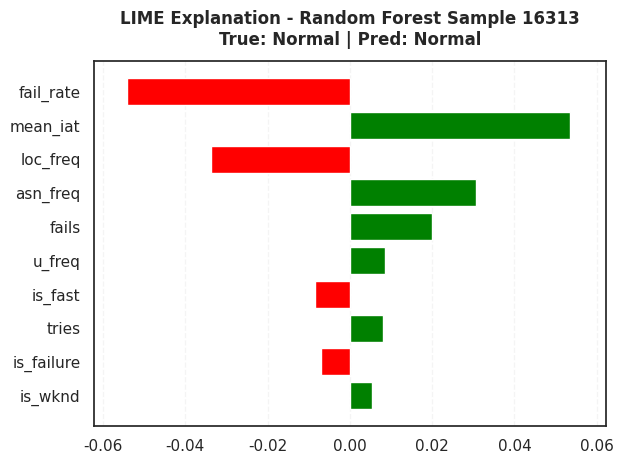


Random Forest LIME completed.


In [ ]:
import numpy as np
import pandas as pd
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import warnings

warnings.filterwarnings('ignore')

class_name_map = {0: 'Normal', 1: 'Attack'}
model_classes = list(rf.classes_)
class_names = [class_name_map[int(c)] for c in model_classes]

lime_feature_names = X_train.columns.tolist()

def predict_proba_lime_rf(X_input):
    X_input = np.atleast_2d(np.asarray(X_input))
    X_input = pd.DataFrame(X_input, columns=lime_feature_names)
    return rf.predict_proba(X_input)

lime_background = X_train.sample(n=min(5000, len(X_train)), random_state=42).values

explainer_lime_rf = lime.lime_tabular.LimeTabularExplainer(
    training_data=lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)

sample_idx = int(np.random.randint(0, len(X_test)))
sample_values = X_test.iloc[sample_idx].values

pred_probs = predict_proba_lime_rf(sample_values)
pred_class_idx = int(np.argmax(pred_probs, axis=1)[0])
pred_class_value = model_classes[pred_class_idx]
pred_class_name = class_name_map[int(pred_class_value)]
confidence = pred_probs[0][pred_class_idx]

true_label = int(y_test.iloc[sample_idx])
true_label_name = class_name_map[true_label]

exp = explainer_lime_rf.explain_instance(
    data_row=sample_values,
    predict_fn=predict_proba_lime_rf,
    num_features=10,
    labels=(pred_class_idx,),
    num_samples=3000
)

print(f"\nSelected Sample: {sample_idx}")
print(f"True Label: {true_label_name}")
print(f"RF Prediction: {pred_class_name} (Confidence: {confidence:.4f})")

if true_label != int(pred_class_value):
    print("MISCLASSIFICATION!")

fig = exp.as_pyplot_figure(label=pred_class_idx)
ax = fig.axes[0]

for line in ax.lines:
    line.remove()

plt.title(
    f"LIME Explanation - Random Forest Sample {sample_idx}\n"
    f"True: {true_label_name} | Pred: {pred_class_name}",
    fontsize=12,
    fontweight='bold',
    pad=12
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: '0.00' if abs(x) < 0.005 else f'{x:.2f}')
)

ax.xaxis.set_major_locator(MultipleLocator(0.02))

weights = [val for feature, val in exp.as_list(label=pred_class_idx)]
# حساب أقصى قيمة مطلقة + هامش صغير (15%) لكي لا تلامس الأعمدة الحافة
max_abs_weight = max(abs(min(weights)), abs(max(weights))) 
x_limit = max_abs_weight * 1.15 
ax.set_xlim(-x_limit, x_limit) 

ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(f'LIME_RF_Sample_{sample_idx}.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nRandom Forest LIME completed.")

Final Summary with All Metrics

In [ ]:
y_train_pred = rf.predict(X_train_scaled)
y_val_pred = rf.predict(X_val_scaled)
y_test_pred = rf.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')

report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=['Normal', 'Attack'],
    output_dict=True,
    zero_division=0
)

attack_recall = report['Attack']['recall']
normal_recall = report['Normal']['recall']
far_rate = 1 - normal_recall

top_features = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

start_time = time.time()
xgb_model.predict(X_test_scaled)
end_time = time.time()
inference_speed = (end_time - start_time) / len(X_test_scaled)

print("\n" + "=" * 70)
print("FINAL SUMMARY - ALL METRICS")
print("=" * 70)

print(f"""╔══════════════════════════════════════════════════════════╗
║                 MODEL PERFORMANCE SUMMARY                ║
╠══════════════════════════════════════════════════════════╣
║
║  ACCURACY:
║  • Training: {train_acc:.2%}
║  • Test: {test_acc:.2%}
║  • Validation: {val_acc:.2%}
║
║  SECURITY METRICS:
║  • Attack Detection Rate (Recall): {attack_recall:.2%}
║  • False Alarm Rate: {far_rate:.2%}
║  • System Reliability (Attack Precision): {report['Attack']['precision']:.2%}
║
║  MODEL EFFICIENCY:
║  • Overall Accuracy: {test_acc:.2%}
║  • F1-Score (Weighted): {test_f1:.2%}
║  • Inference Speed: {inference_speed*1000:.4f} ms/sample
║
║  PER-CLASS F1-SCORES:
║  • Normal: {report['Normal']['f1-score']:.2%}
║  • Attack: {report['Attack']['f1-score']:.2%}
║
║  TOP FEATURES INFLUENCING DETECTION:
║  1. {top_features.iloc[0]['Feature']}
║  2. {top_features.iloc[1]['Feature']}
║  3. {top_features.iloc[2]['Feature']}
║
║  DATA DISTRIBUTION:
║  • Total samples: {len(df)}
║  • Features used: {len(X_train_scaled.columns)}
║  • Train/Test/Val: {len(X_train_scaled)}/{len(X_test_scaled)}/{len(X_val_scaled)}
║
╚══════════════════════════════════════════════════════════╝
""")

NameError: name 'xgb_model' is not defined